Upload data

In [1]:
import numpy as np
import pandas as pd
import json
import talib

# for graphs
import matplotlib.pyplot as plt

In [2]:
def sort_by_col(sort_col, dfs):
    """soring set of df in one sorting style."""  
    return [df.sort_values(sort_col) for df in dfs]    

In [3]:
def prepare_dataset(path, parquet=True):
    """Making all columns in one style."""    
    if parquet:
        df = pd.read_parquet(path)
    else:
        df = pd.read_csv(path)
    df.columns = df.columns.str.lower().str.strip().str.replace(' ', '_')
    if 'date' in df.columns:
        df['date'] = df['date'].astype('datetime64[ns]')
    return df

In [4]:
def correct_values(df, column_names, coeff_name):
    """Adjusting prices by coefficient which calculated in separate column."""    
    for column in column_names:
        df[column + '_adj'] = df[column] * df[coeff_name]
    return df

In [5]:
def get_talib_patterns(df: pd.DataFrame) -> pd.DataFrame:
    """All TA-Lib candlestick patterns for ONE ticker: 100 / -100 / 0."""
    o = df['open_adj'].to_numpy(dtype='float64')
    h = df['high_adj'].to_numpy(dtype='float64')
    l = df['low_adj'].to_numpy(dtype='float64')
    c = df['adj_close'].to_numpy(dtype='float64')
    patterns = {name.lower(): getattr(talib, name)(o, h, l, c)
                for name in talib.get_function_groups()['Pattern Recognition']}
    return pd.DataFrame(patterns, index=df.index)

In [6]:
def get_talib_indicators(df: pd.DataFrame) -> pd.DataFrame:
    """TA-Lib indicators for ONE ticker (rows sorted by date), on adjusted prices."""
    o = df['open_adj'].to_numpy(dtype='float64')
    h = df['high_adj'].to_numpy(dtype='float64')
    l = df['low_adj'].to_numpy(dtype='float64')
    c = df['adj_close'].to_numpy(dtype='float64')
    v = df['volume'].to_numpy(dtype='float64')


    ind = {}
    # Momentum
    ind['adx'] = talib.ADX(h, l, c, timeperiod=14)
    ind['adxr'] = talib.ADXR(h, l, c, timeperiod=14)
    ind['apo'] = talib.APO(c, fastperiod=12, slowperiod=26, matype=0)
    ind['aroon_down'], ind['aroon_up'] = talib.AROON(h, l, timeperiod=14)
    ind['aroonosc'] = talib.AROONOSC(h, l, timeperiod=14)
    ind['bop'] = talib.BOP(o, h, l, c)
    ind['cci'] = talib.CCI(h, l, c, timeperiod=14)
    ind['cmo'] = talib.CMO(c, timeperiod=14)
    ind['dx'] = talib.DX(h, l, c, timeperiod=14)
    ind['macd'], ind['macdsignal'], ind['macdhist'] = talib.MACD(c, fastperiod=12, slowperiod=26, signalperiod=9)
    ind['mfi'] = talib.MFI(h, l, c, v, timeperiod=14)
    ind['minus_di'] = talib.MINUS_DI(h, l, c, timeperiod=14)
    ind['plus_di'] = talib.PLUS_DI(h, l, c, timeperiod=14)
    ind['mom'] = talib.MOM(c, timeperiod=10)
    ind['ppo'] = talib.PPO(c, fastperiod=12, slowperiod=26, matype=0)
    ind['roc'] = talib.ROC(c, timeperiod=10)
    ind['rsi'] = talib.RSI(c, timeperiod=14)
    ind['slowk'], ind['slowd'] = talib.STOCH(h, l, c, fastk_period=5, slowk_period=3, slowk_matype=0,
                                            slowd_period=3, slowd_matype=0)
    ind['fastk_rsi'], ind['fastd_rsi'] = talib.STOCHRSI(c, timeperiod=14, fastk_period=5, fastd_period=3, fastd_matype=0)
    ind['trix'] = talib.TRIX(c, timeperiod=30)
    ind['ultosc'] = talib.ULTOSC(h, l, c, timeperiod1=7, timeperiod2=14, timeperiod3=28)
    ind['willr'] = talib.WILLR(h, l, c, timeperiod=14)
    # Volume
    ind['ad'] = talib.AD(h, l, c, v)
    ind['adosc'] = talib.ADOSC(h, l, c, v, fastperiod=3, slowperiod=10)
    ind['obv'] = talib.OBV(c, v)
    # Volatility
    ind['atr'] = talib.ATR(h, l, c, timeperiod=14)
    ind['natr'] = talib.NATR(h, l, c, timeperiod=14)
    # Cycle
    ind['ht_dcperiod'] = talib.HT_DCPERIOD(c)
    ind['ht_dcphase'] = talib.HT_DCPHASE(c)
    ind['ht_phasor_inphase'], ind['ht_phasor_quadrature'] = talib.HT_PHASOR(c)
    ind['ht_sine_sine'], ind['ht_sine_leadsine'] = talib.HT_SINE(c)
    ind['ht_trendmode'] = talib.HT_TRENDMODE(c)


    return pd.DataFrame(ind, index=df.index)


In [7]:
df_prices = prepare_dataset('../data/prices.parquet')
df_index = prepare_dataset('../data/index.parquet') 
df_bonds = prepare_dataset('../data/bonds_10y.parquet')
df_deposit = prepare_dataset('../data/ecb_deposit_rate.parquet')
df_tickers = prepare_dataset("../tickers.csv", parquet=False)

*Correcting price*

In [8]:
df_prices = df_prices.sort_values(by=['ticker', 'date'])
df_prices['factor'] = df_prices.adj_close / df_prices.close
column_names = ['open', 'high', 'low'] 
df_prices = correct_values(df_prices, column_names, 'factor')

len(df_prices[df_prices['close'] == 0])

0

*Manually defined features*

In [9]:
# grown for previous periods
for i in [1, 3, 7, 30, 90, 252]:
    df_prices['growth_' + str(i) + 'd'] = df_prices['adj_close'] / df_prices.groupby('ticker')['adj_close'].shift(i)

# daily return
df_prices['daily_return'] = df_prices.groupby('ticker')['adj_close'].pct_change()

#volatility (30 days)
df_prices['volatility_30d'] = df_prices.groupby('ticker')['daily_return'].transform(lambda x: x.rolling(30).std())

#daily turnover
df_prices['turnover'] = df_prices['volume'] * df_prices ['close'] 
df_prices['daily_turnover'] = df_prices.groupby('ticker')['turnover'].transform(lambda x: x.rolling(30).mean())

*Add Ta-lib indicators and candlestick*

In [10]:
parts = [get_talib_indicators(group) for _, group in df_prices.groupby('ticker')]
df_prices = df_prices.join(pd.concat(parts))

parts = [get_talib_patterns(group) for _, group in df_prices.groupby('ticker')]
df_prices = df_prices.join(pd.concat(parts))

*Preparing and merging df_prices, df_bonds, df_deposit, df_tickers*

In [11]:
# calculating spread
df_bonds['spread_gr_de'] = df_bonds['gr_10y'] - df_bonds['de_10y']

In [12]:
# shifting dates
# to the next month
df_bonds['date'] = df_bonds['date'] + pd.DateOffset(months=1)
# plus one day
df_deposit['date'] = df_deposit['date'] + pd.Timedelta(days=1)
#sorting all df by price
df_prices, df_bonds, df_deposit = sort_by_col('date', [df_prices, df_bonds, df_deposit])
#merging all dfs
df_final = pd.merge_asof(df_prices, df_bonds, on="date")
df_final = pd.merge_asof(df_final, df_deposit, on="date")
df_final = pd.merge(df_final, df_tickers[['ticker','sector']], on='ticker', how='left')
#adding calendar
df_final['month'] = df_final.date.dt.month
df_final['weekday'] = df_final.date.dt.day_of_week
df_final['wom'] = (df_final.date.dt.day - 1)// 7 + 1

In [13]:
#making dummies
cols = ['month', 'weekday', 'wom', 'ticker', 'sector'];
dummies = pd.get_dummies(df_final[cols], columns=cols, dtype=int)
df_final = pd.concat([df_final, dummies], axis=1)

In [14]:
#aim
df_final = df_final.sort_values(['ticker', 'date'])
df_final['growth_future_30d'] =  df_final.groupby('ticker')['adj_close'].shift(-30) / df_final['adj_close']
df_final['is_positive_growth_30d_future'] = (
    (df_final['growth_future_30d'] > 1)
    .where(df_final['growth_future_30d'].notna())
    .astype('Int64')
)

*Creating the list of columns* 

In [15]:
#columns we will predict
TO_PREDICT = ['is_positive_growth_30d_future', 'growth_future_30d']
#dummies columns
DUMMIES = dummies.columns.tolist()
#gatering the list of exclusions columns
EXCLUSIONS = ['date', 'ticker', 'sector', 'factor', 'volume', 'turnover', 'month', 'weekday', 'wom']
ADJUSTED_PRICES = [col for col in df_final.columns if any(sub in col for sub in ('_adj', 'adj_'))]
RAW_PRICES = [col.replace('_adj', '').replace('adj_', '') for col in ADJUSTED_PRICES]
EXCLUSIONS.extend(ADJUSTED_PRICES)
EXCLUSIONS.extend(RAW_PRICES)
#now making numerical columns. all except we gathered up here
all_excluded = {*TO_PREDICT, *DUMMIES, *EXCLUSIONS}
NUMERICAL = [col for col in df_final.columns if col not in all_excluded]

*Checking for duplicates raws and working with NaN*

In [16]:
#checking for duplicates
has_dups = df_final.duplicated(subset=['date', 'ticker']).any()
print(has_dups)

False


In [17]:
#checking NaN columns
df_final.isna().sum()[lambda x: x > 0].sort_values(ascending=False)

growth_252d                      8316
growth_90d                       2970
trix                             2904
ht_dcphase                       2079
ht_sine_sine                     2079
ht_sine_leadsine                 2079
adxr                             1320
macdsignal                       1089
macd                             1089
macdhist                         1089
ht_dcperiod                      1056
ht_phasor_quadrature             1056
ht_phasor_inphase                1056
is_positive_growth_30d_future     990
volatility_30d                    990
growth_future_30d                 990
growth_30d                        990
daily_turnover                    957
ultosc                            924
adx                               891
ppo                               825
apo                               825
fastd_rsi                         660
fastk_rsi                         660
de_10y                            570
gr_10y                            570
spread_gr_de

all NaNs as anticipated. 

In [18]:
#checking for inf 
mask = np.isinf(df_final.select_dtypes(include=np.number)).any(axis=1)
df_final[mask]

,date,adj_close,close,high,low,open,volume,ticker,factor,open_adj,...,sector_Consumer Cyclical,sector_Consumer Defensive,sector_Energy,sector_Financial Services,sector_Industrials,sector_Real Estate,sector_Technology,sector_Utilities,growth_future_30d,is_positive_growth_30d_future


no inf values

*Checking base rate*

In [19]:
df_final[TO_PREDICT].describe()

,is_positive_growth_30d_future,growth_future_30d
count,86679.0,86679.000000
mean,0.573738,1.031594
std,0.494536,0.155525
min,0.0,0.136402
25%,0.0,0.957647
50%,1.0,1.018057
75%,1.0,1.092442
max,1.0,5.411472


Base rate = 0.57. in 57% the price were increasing after 30 days. 

*Saving final data frame and columns list*

In [20]:
#saving final df
df_final.to_parquet('../data/features.parquet', index=False)
#saving columns sets in json
to_save = {'TO_PREDICT': TO_PREDICT, 'DUMMIES': DUMMIES, 'NUMERICAL': NUMERICAL}
with open("../data/feature_set.json", "w", encoding="utf-8") as f:
  json.dump(to_save, f, indent=2)

Hystograms

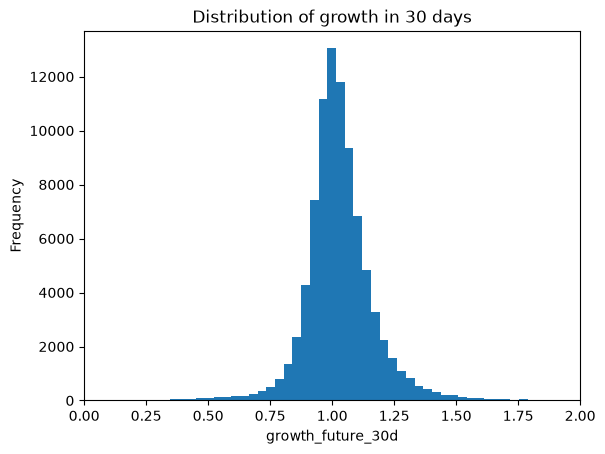

In [21]:
df_final['growth_future_30d'].plot.hist(bins=150)
plt.title('Distribution of growth in 30 days')
plt.xlabel('growth_future_30d')
plt.xlim(0, 2.0)
plt.show()

Growth in 30 days looks like a bell, center is a bit above 1. Most values are between 0.8 and 1.25, big moves (±50%) are rare. Center is shifted right, that's why base rate is 0.57.

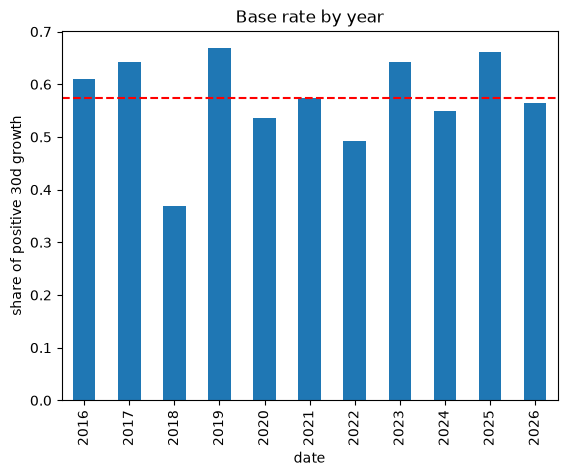

In [22]:
by_year = df_final.groupby(df_final['date'].dt.year)['is_positive_growth_30d_future'].mean()
by_year.plot.bar()
plt.axhline(0.574, color='red', linestyle='--')
plt.title('Base rate by year')
plt.ylabel('share of positive 30d growth')
plt.show()

Base rate is very different by year: 0.37 in 2018, around 0.67 in 2019 and 2025. Bad years (2018, 2022) were probably market falls. So precision on test should be compared with base rate of the same period, not with 0.57.

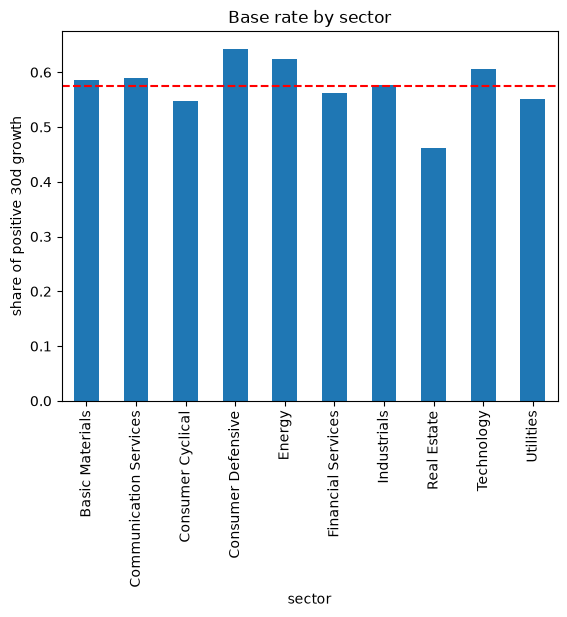

In [23]:
by_year = df_final.groupby(df_final['sector'])['is_positive_growth_30d_future'].mean()
by_year.plot.bar()
plt.axhline(0.574, color='red', linestyle='--')
plt.title('Base rate by sector')
plt.ylabel('share of positive 30d growth')
plt.show()

Most sectors are close to 0.57. Consumer Defensive and Energy are higher, Real Estate is the lowest (0.46). Only few stocks in each sector, so the difference can be because of single companies.

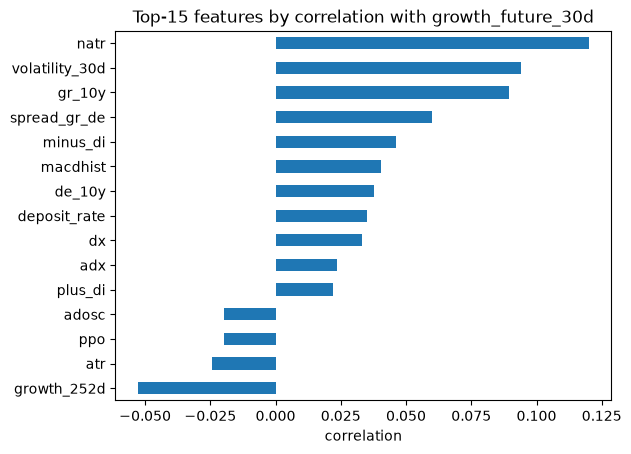

In [24]:
corr = df_final[NUMERICAL].corrwith(df_final['growth_future_30d']).dropna()
top = corr.loc[corr.abs().sort_values(ascending=False).index[:15]]


top.sort_values().plot.barh()
plt.title('Top-15 features by correlation with growth_future_30d')
plt.xlabel('correlation')
plt.show()

All correlations are small (less than 0.13), it's normal for stocks. Top positive: volatility (natr, volatility_30d) and Greek bonds / spread. After volatile or stress periods prices were going up. growth_252d is negative: after strong year next month is a bit weaker. Trees can find non-linear relations too, so we check feature importance after training.